In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay



In c:\Users\PC\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\bmh.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.
In c:\Users\PC\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\classic.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.
In c:\Users\PC\anaconda3\Lib\site-packages\matplotlib\mpl-data\stylelib\_classic_test_patch.mplstyle: The text.kerning_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.


Dataset shape: (891, 11)

Data types:
 PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Survived.1     float64
dtype: object

Missing values:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Survived.1     473
dtype: int64

Summary statistics:
        PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.

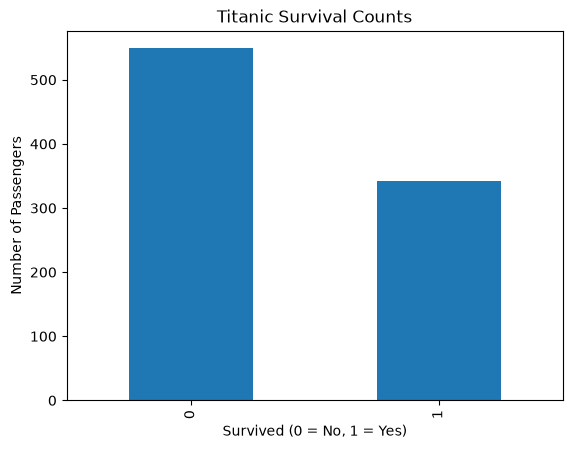

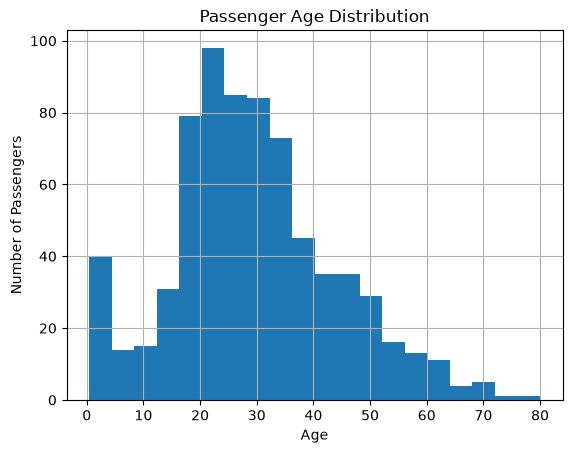

In [2]:
# 1. Load and explore the data
df = pd.read_csv("titanic.csv")
print("Dataset shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nSummary statistics:\n", df.describe())
print("\nSurvival counts:\n", df["Survived"].value_counts())
print("\nSurvival rate by sex:\n", df.groupby("Sex")["Survived"].mean())

df["Survived"].value_counts().sort_index().plot(kind="bar")
plt.title("Titanic Survival Counts")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

df["Age"].hist(bins=20)
plt.title("Passenger Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()



In [3]:
# 2. Choose input features and the target
X = df[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare"]]
y = df["Survived"]

# 3. Split the dataset before fitting preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))




Training samples: 712
Testing samples: 179


In [4]:
# 4. Make preprocessing pipelines
numeric_features = ["Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Sex", "Pclass"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])



In [5]:
# 5. Connect preprocessing and machine learning
pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])



In [6]:
# 6. Try hyperparameter combinations with cross-validation
param_grid = {
    "model__max_depth": [2, 3, 4, 5],
    "model__min_samples_leaf": [1, 3, 5]
}
grid = GridSearchCV(pipeline, param_grid, cv=5, scoring="f1")
grid.fit(X_train, y_train)
print("\nBest parameters:", grid.best_params_)
print("Best cross-validation F1:", round(grid.best_score_, 3))




Best parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 5}
Best cross-validation F1: 0.739



Test accuracy: 0.749
Test precision: 0.722
Test recall: 0.565
Test F1: 0.634

Confusion matrix:
 [[95 15]
 [30 39]]


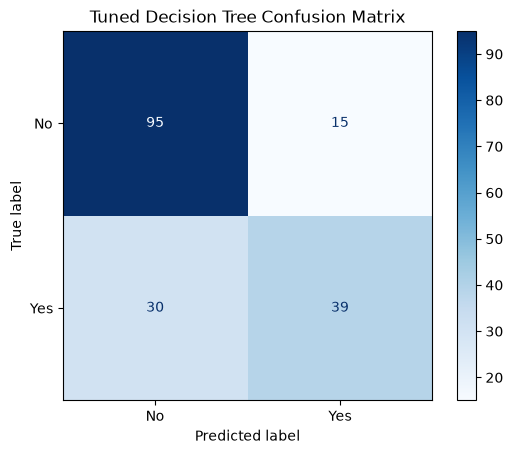

In [7]:
# 7. Evaluate the final model on the untouched test data
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)
print("\nTest accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Test precision:", round(precision_score(y_test, y_pred), 3))
print("Test recall:", round(recall_score(y_test, y_pred), 3))
print("Test F1:", round(f1_score(y_test, y_pred), 3))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["No", "Yes"], cmap="Blues"
)
plt.title("Tuned Decision Tree Confusion Matrix")
plt.show()



In [8]:
# 8. Make a prediction on one new passenger
new_passenger = pd.DataFrame([{
    "Pclass": 3, "Sex": "female", "Age": 25,
    "SibSp": 0, "Parch": 0, "Fare": 7.5
}])
new_prediction = best_model.predict(new_passenger)[0]
print("New passenger prediction:", "Survived" if new_prediction == 1 else "Did not survive")


New passenger prediction: Survived
